#### For demo:
- drop image: 1. predict real/fake 2. predict model (also detect watermark)
- guessing game? - compare guesses to model guesses, compare total percents (see if can beat model)

#### Data
##### Label_A (Binary Classification)
- Real  0    Image is a real photograph/non-AI generated.
- AI-Generated  1   Image was created by an AI generation model.
##### Label_B (Model Source Identification)
- Real	0	Real image (no AI generation involved).
- SD21	1	Generated by Stable Diffusion 2.1.
- SDXL	2	Generated by Stable Diffusion XL.
- SD3	3	Generated by Stable Diffusion 3.
- DALLE3	4	Generated by DALL-E 3.
- Midjourney	5	Generated by Midjourney 6.

In [1]:
import torch
import torchvision

# NVIDIA GPU available (should be True for Luke)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
# Set up image transforms, datasets, and data loaders

from pathlib import Path
from datasets import load_dataset
from torch.utils.data import DataLoader

from preprocessing import preprocess

batch_size = 64

train = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset", split="train").with_transform(preprocess)
val = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset", split="validation").with_transform(preprocess)
test = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset", split="test").with_transform(preprocess)

trainloader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
valloader = DataLoader(val, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
testloader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)


c:\Users\butch\BDAA-Human-AI-Image-Detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Set up model for transfer learning

import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

model = resnet50(weights=ResNet50_Weights.DEFAULT)

for param in model.parameters():
    param.requires_grad = False

# Replace the final layer with a new one that has 2 output classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

model.to(device)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [4]:
# set up optimizer

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
# optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [5]:
# Train/eval loop

best_accuracy = 0
miss_count = 0
for epoch in range(10):
    model.train()
    running_loss = 0.0

    for i, batch in enumerate(trainloader, 0):
        images = batch["Image"].to(device)
        binary_labels = batch["Label_A"].to(device)
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, binary_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 75 == 74:    # print every 75 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 75:.3f}')
            running_loss = 0.0
    print(f'Finished epoch {epoch + 1}')
    
    # Validation
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for batch in valloader:
            images = batch["Image"].to(device)
            binary_labels = batch["Label_A"].to(device)
            # calculate outputs by running images through the network
            outputs = model(images)
            # the class with the highest energy is what we choose as prediction
            _, predicted = torch.max(outputs, 1)
            total += binary_labels.size(0)
            correct += (predicted == binary_labels).sum().item()

    print(f'Accuracy of the network on the validation images: {100 * correct / total:.2f} %')

    if correct / total > best_accuracy:
        best_accuracy = correct / total
        torch.save(model, './models/ResNet50Baseline.pth')
        miss_count = 0
    else:
        miss_count += 1
        if miss_count >= 3:
            print("Performance stopped improving, stopping early.")
            break

print('Finished Training')

[1,    75] loss: 0.411
[1,   150] loss: 0.307
[1,   225] loss: 0.292
[1,   300] loss: 0.260
[1,   375] loss: 0.253
[1,   450] loss: 0.216
[1,   525] loss: 0.224
[1,   600] loss: 0.219
Finished epoch 1
Accuracy of the network on the validation images: 91.67 %
[2,    75] loss: 0.212
[2,   150] loss: 0.207
[2,   225] loss: 0.204
[2,   300] loss: 0.195
[2,   375] loss: 0.182
[2,   450] loss: 0.202
[2,   525] loss: 0.195
[2,   600] loss: 0.187
Finished epoch 2
Accuracy of the network on the validation images: 92.84 %
[3,    75] loss: 0.181
[3,   150] loss: 0.183
[3,   225] loss: 0.175
[3,   300] loss: 0.174
[3,   375] loss: 0.180
[3,   450] loss: 0.190
[3,   525] loss: 0.173
[3,   600] loss: 0.189
Finished epoch 3
Accuracy of the network on the validation images: 92.87 %
[4,    75] loss: 0.169
[4,   150] loss: 0.179
[4,   225] loss: 0.166
[4,   300] loss: 0.173
[4,   375] loss: 0.183
[4,   450] loss: 0.166
[4,   525] loss: 0.161
[4,   600] loss: 0.168
Finished epoch 4
Accuracy of the networ

              precision    recall  f1-score   support

        Real      0.873     0.690     0.771      1500
AI-generated      0.940     0.980     0.960      7500

    accuracy                          0.932      9000
   macro avg      0.907     0.835     0.865      9000
weighted avg      0.929     0.932     0.928      9000

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[1035  465]
 [ 151 7349]]
Balanced accuracy: 0.8349
Brier score (lower is better): 0.0514
Log loss (lower is better): 0.1801
ROC-AUC (higher is better): 0.9583


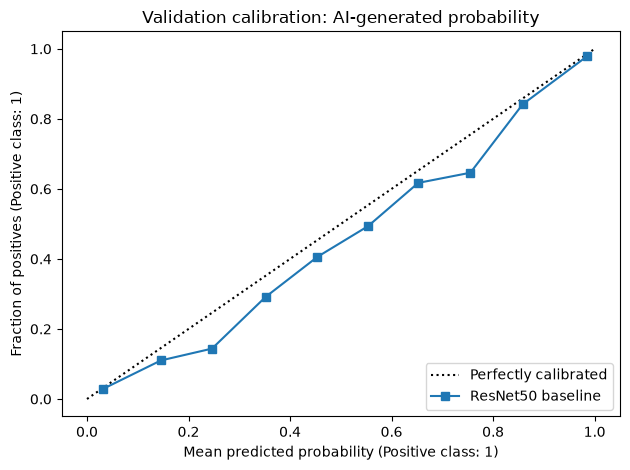

In [6]:
# Get detailed metrics for the current model on the validation set

import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability = [], [], []

model.eval()
with torch.no_grad():
    for batch in valloader:
        images = batch["Image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["Label_A"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "AI-generated"],
    digits=3,
    zero_division=0,
))

print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
print(f"Brier score (lower is better): {brier_score_loss(y_true, y_ai_probability):.4f}")
print(f"Log loss (lower is better): {log_loss(y_true, y_ai_probability, labels=[0, 1]):.4f}")
print(f"ROC-AUC (higher is better): {roc_auc_score(y_true, y_ai_probability):.4f}")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="ResNet50 baseline",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()
